In [1]:
import pandas as pd
import numpy as np

In [7]:
df = pd.read_csv('/content/auto-mpg.csv')

In [8]:
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger


In [9]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [10]:
df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger
397,31.0,4,119.0,82,2720,19.4,82,1,chevy s-10


In [ ]:
df.describe()

,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


In [14]:
df.dtypes

,0
mpg,float64
cylinders,int64
displacement,float64
horsepower,object
weight,int64
acceleration,float64
model year,int64
origin,int64
car name,object


In [15]:
df.shape

(398, 9)

In [16]:
df.info

<bound method DataFrame.info of       mpg  cylinders  displacement horsepower  weight  acceleration  \
0    18.0          8         307.0        130    3504          12.0   
1    15.0          8         350.0        165    3693          11.5   
2    18.0          8         318.0        150    3436          11.0   
3    16.0          8         304.0        150    3433          12.0   
4    17.0          8         302.0        140    3449          10.5   
..    ...        ...           ...        ...     ...           ...   
393  27.0          4         140.0         86    2790          15.6   
394  44.0          4          97.0         52    2130          24.6   
395  32.0          4         135.0         84    2295          11.6   
396  28.0          4         120.0         79    2625          18.6   
397  31.0          4         119.0         82    2720          19.4   

     model year  origin                   car name  
0            70       1  chevrolet chevelle malibu  
1            70       1          buick skylark 320  
2            70       1         plymouth satellite  
3            70       1              amc rebel sst  
4            70       1                ford torino  
..          ...     ...                        ...  
393          82       1            ford mustang gl  
394          82       2                  vw pickup  
395          82       1              dodge rampage  
396          82       1                ford ranger  
397          82       1                 chevy s-10  

[398 rows x 9 columns]>

In [17]:
# separete numeric and categorical columns
numeric_columns = df.select_dtypes(include=['int64','float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

In [19]:
# display results
print("Numeric Columns:")
print(numeric_columns)
print("\nCategorical Columns:")
print(categorical_columns)

Numeric Columns:
Index(['mpg', 'cylinders', 'displacement', 'weight', 'acceleration',
       'model year', 'origin'],
      dtype='object')

Categorical Columns:
Index(['horsepower', 'car name'], dtype='object')


In [20]:
#performing data clining
#handling missing data
#removing null data

In [21]:
#show initial missing values count
print("missing values before clining:")
print(df.isnull().sum())

missing values before clining:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


In [23]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Convert horsepower to numeric, replacing any non-numeric values (like '?') with NaN
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')

# Fill any missing values in horsepower with the median value
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

# Select Numeric columns
X = df[['mpg','cylinders','displacement','horsepower','weight','acceleration','model year']]

# rescale data
scaler = MinMaxScaler()
rescaled_data = scaler.fit_transform(X)

# Dispaly result
print(rescaled_data)

[[0.2393617  1.         0.61757106 ... 0.5361497  0.23809524 0.        ]
 [0.15957447 1.         0.72868217 ... 0.58973632 0.20833333 0.        ]
 [0.2393617  1.         0.64599483 ... 0.51686986 0.17857143 0.        ]
 ...
 [0.61170213 0.2        0.17312661 ... 0.19336547 0.21428571 1.        ]
 [0.50531915 0.2        0.13436693 ... 0.2869294  0.63095238 1.        ]
 [0.58510638 0.2        0.13178295 ... 0.31386447 0.67857143 1.        ]]


In [27]:
from sklearn.preprocessing import LabelEncoder

# Create labelencoder object
encoder = LabelEncoder()

# encode categorical column
df['car name'] = encoder.fit_transform(df['car name'])

# dispaly encoded data
print(df[['car name']].head())

   car name
0        49
1        36
2       231
3        14
4       161


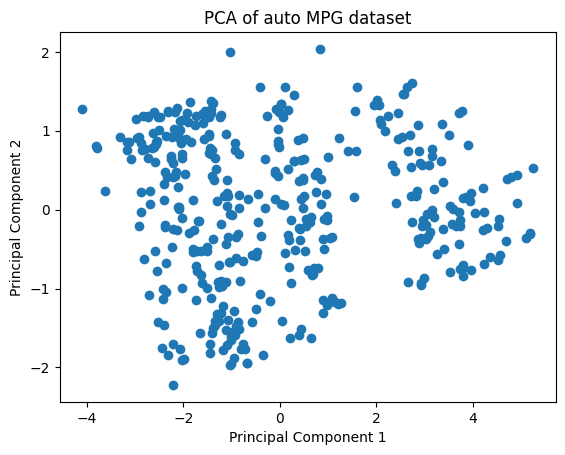

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

#select numeric features
X = df[['mpg', 'cylinders', 'displacement', 'horsepower' ,'weight', 'acceleration',
       'model year',]]

#handle missing values
X = X.fillna(X.mean())

#standardize the data
X_scaler = StandardScaler().fit_transform(X)

#apply pca
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaler)

#plot
plt.scatter(principal_components[:,0], principal_components[:,1])
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of auto MPG dataset')
plt.show()